## Bigramas estadísticos vs Bigramas de Redes Neuronales

In [2]:
import idna

# def utf8_to_punycode(text: str) -> str:
#     """Encodes a UTF-8 string to its Punycode representation."""
#     return idna.encode(text).decode('ascii')

def punyencode(text: str) -> str:
    """Encodes a UTF-8 string to its Punycode representation, handling spaces by encoding each word separately."""
    
    return " ".join([idna.encode(word).decode('ascii') for word in text.split()])
    
def punydecode(punycode: str) -> str:
    """Decodes a Punycode string back to UTF-8."""
    #return idna.decode(punycode)
    return " ".join([idna.decode(word) for word in punycode.split()])

def process_name(name):
    name = name.lower()
    for n in name.split():
        if len(n) < 2:
            return ''
    try:
        return punyencode(name)
    except:
        #print(f'Cant convert {name}')
        return ''

import numpy as np

dataset = open("data/city_names_puny.txt", 'r').read().split('\n')

In [11]:
charset = ['*'] + sorted(list(set([y for x in dataset for y in x])))
ctoi = {c:i for i, c in enumerate(charset)}
itoc = {i:c for i, c in enumerate(charset)}

### Contando bigramas
Acá contamos los bigramas a mano y los metemos en una matriz

In [37]:
bigram_count = np.zeros((len(charset), len(charset))).astype(int)
bigram_count
for d in dataset:  # <== remove [:10] to run for all examples
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        bigram_count[ctoi[c1], ctoi[c2]] += 1
bigram_count += 1 
bigram_count

array([[    2,     1,     1, ..., 23497,  1143,  1368],
       [    1,     1,     1, ...,  6163,   219,   258],
       [    1,     1, 29158, ...,  1112,   936,  1074],
       ...,
       [  477,    55,   228, ...,    34,    39,    19],
       [ 5020,   842,  1160, ...,    36,   321,    84],
       [  973,   322,   782, ...,    31,   381,   502]], shape=(40, 40))

In [38]:
bigram_prob = bigram_count/bigram_count.sum(axis=1, keepdims=True)

In [41]:
ll = 0
i = 0
for ciudad in dataset:
    for c1, c2 in zip(ciudad, ciudad[1:]):
        ll += -np.log(bigram_prob[ctoi[c1]][ctoi[c2]])
        i += 1
ll/i

np.float64(2.752153426674224)

### El modelo de redes neuronales

In [92]:
import torch
from torch.nn import functional as F
xs, ys = [], []
nclasses = len(charset)
# definición del modelo
g = torch.Generator().manual_seed(42)
W = torch.randn((nclasses, nclasses), generator=g, requires_grad=True)

# genero mi dataset de training ()
for d in dataset: 
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        xs.append(ctoi[c1])
        ys.append(ctoi[c2])
        #print(c1, c2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
nsamples = xs.nelement()  # <== needed for index probabilities

iterations = 400
lr = 100.

xenc = F.one_hot(xs,num_classes=nclasses).float()
print(nsamples)

losses = []

# training loop
for k in range(iterations):
    # forward pass
    logits = xenc @ W
    # loss
    counts = logits.exp()
    probs = counts / counts.sum(axis=1, keepdims=True)
    loss = -probs[range(nsamples), ys].log().mean() + 0.01 * (W**2).mean()
    losses.append(loss.item())
    print(f'step {k}/{iterations}: {loss.item()}', end='\r')

    # zero grad
    W.grad = None
    
    # backwards pass
    loss.backward()
    
    #update
    W.data += -lr * W.grad

1737336


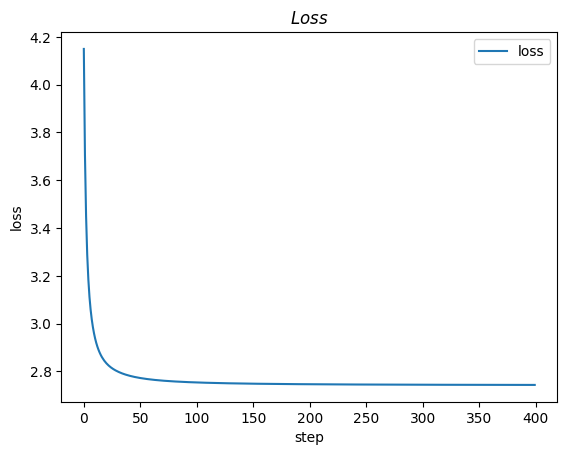

In [99]:
import matplotlib.pyplot as plt
plt.plot(losses, label='loss')
plt.ylabel('loss')
plt.xlabel('step')
plt.title('$Loss$')
plt.legend()
plt.show()

In [108]:
# training loop
lr = 100.
for k in range(iterations):
    # forward pass
    logits = xenc @ W
    # loss
    counts = logits.exp()
    probs = counts / counts.sum(axis=1, keepdims=True)
    loss = -probs[range(nsamples), ys].log().mean() # + 0.01 * (W**2).mean()
    print(f'step {k}/{iterations}: {loss.item()}', end='\r')

    # zero grad
    W.grad = None
    
    # backwards pass
    loss.backward()
    
    #update
    W.data += -lr * W.grad

In [109]:
nn_probs = W.exp()/W.exp().sum(axis=1,keepdims=True)

In [80]:
sum(nn_probs[0])


tensor(1.0000, grad_fn=<AddBackward0>)

In [110]:
torch.allclose(torch.tensor(bigram_prob,dtype=float), nn_probs.to(float))

False

In [107]:
nn_probs

tensor([[1.4196e-04, 1.3894e-04, 1.3879e-04,  ..., 1.6327e-01, 7.8660e-03,
         9.4305e-03],
        [3.7390e-04, 4.0044e-04, 3.8691e-04,  ..., 1.2770e-01, 4.3154e-03,
         5.1302e-03],
        [2.6911e-04, 2.6868e-04, 3.0003e-01,  ..., 1.1411e-02, 9.6001e-03,
         1.1020e-02],
        ...,
        [1.3859e-02, 1.3314e-03, 6.5144e-03,  ..., 9.0306e-04, 1.0924e-03,
         7.7741e-04],
        [2.3729e-01, 3.9552e-02, 5.4605e-02,  ..., 1.8309e-03, 1.4869e-02,
         3.6929e-03],
        [6.4383e-02, 2.1028e-02, 5.1670e-02,  ..., 2.3827e-03, 2.4964e-02,
         3.3027e-02]], grad_fn=<DivBackward0>)

In [103]:
bigram_prob

array([[1.38999896e-05, 6.94999479e-06, 6.94999479e-06, ...,
        1.63304028e-01, 7.94384404e-03, 9.50759287e-03],
       [2.07344129e-05, 2.07344129e-05, 2.07344129e-05, ...,
        1.27786187e-01, 4.54083643e-03, 5.34947853e-03],
       [1.02867959e-05, 1.02867959e-05, 2.99942394e-01, ...,
        1.14389170e-02, 9.62844093e-03, 1.10480188e-02],
       ...,
       [1.39989435e-02, 1.61413394e-03, 6.69131889e-03, ...,
        9.97828256e-04, 1.14456771e-03, 5.57609908e-04],
       [2.37128011e-01, 3.97732641e-02, 5.47945205e-02, ...,
        1.70051960e-03, 1.51629665e-02, 3.96787907e-03],
       [6.45782173e-02, 2.13712086e-02, 5.19015066e-02, ...,
        2.05747660e-03, 2.52870512e-02, 3.33178470e-02]], shape=(40, 40))